# 06 · Learning to rank: LambdaMART against the choice model

Search teams usually rank with a learned ranker, typically gradient-boosted trees trained with
LambdaMART, rather than a choice model. This notebook asks whether one would have changed the
phase 4 answer, and keeps three sources of any gain apart:

| Ranker | Features | Trained on | Isolates |
|---|---|---|---|
| L1 | the choice model's 8 attributes | random-order searches | the **algorithm**: trees and a ranking loss against a logit, same inputs |
| L2 | 31: L1's plus within-search comparisons, the hotel's history in ranked traffic, location score 2, competitor prices, search context | random-order searches | the **features** |
| L3 | the same 31 | Expedia-ordered searches, the same number | the **training data**: logs whose top slots are inflated by position |
| L2p | L2's, plus the slot while training; every hotel scored as if in slot 1 | random-order searches | the standard fix for position-biased labels |

**How rankings are judged.** On the same 23,165 held-out random-order searches as phase 4, with
two yardsticks:

1. **NDCG@38 on what users chose**, the ICDM 2013 competition metric (gain 5 for the booked
   hotel, 1 for a clicked one), adjusted for position. Positions in these searches were meant to
   be random, but section 3 finds the same tilt the audit did, and corrects for it by weighting
   each search by how likely its chosen hotel's slot was to be looked at. This needs no
   booking model.
2. **The phase 4 booking model** (expected bookings and value per search). It sees only its own
   eight attributes, so it cannot credit L2 or L3 for anything else they know.

**Status.** Exploratory. The phase 4 decision rule did not include learned rankers, and a
prototype of this comparison was run before the notebook was written, so nothing here replaces
the rule's answer; it informs which arms are worth an online test.

In [1]:
import os
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hotelrank import abtest, audit, choice, ltr, policy, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import read_metrics, show_verdict, write_metrics

N_BOOT = int(os.environ.get("HOTELRANK_N_BOOT", 1000))
COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "prop_location_score2",
           "prop_log_historical_price", "promotion_flag", "prop_id", "srch_length_of_stay", "srch_booking_window",
           "srch_adults_count", "srch_children_count", "srch_room_count", "srch_saturday_night_bool",
           "orig_destination_distance", "comp_n_known", "comp_n_expedia_cheaper", "comp_n_expedia_dearer"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
x = policy.prepare(choice.add_hotel_mean_price(x, full=x))
is_random = x["random_bool"].astype(bool).to_numpy()
x_random, x_ranked = x[is_random], x[~is_random]
del x
gc.collect()

# Ranked searches: one half describes each hotel's record, the other is L3's training pool.
history_src, ranked_pool = ltr.split_ranked(x_ranked)
history = ltr.hotel_history(history_src)
n_history_searches = int(history_src["srch_id"].nunique())
del x_ranked, history_src
gc.collect()

x_random = ltr.add_features(x_random, history)
test = (x_random["srch_id"] % 5 == 0).to_numpy()  # the same hold-out as notebooks 03 and 04
train_all, held_out = x_random[~test], x_random[test]
# early stopping uses a fifth of the training searches, never the held-out ones
valid = ((train_all["srch_id"] // 5) % 5 == 0).to_numpy()
train, valid_set = train_all[~valid], train_all[valid]
print(SOURCE, f"random-order: train {train['srch_id'].nunique():,}, early-stopping {valid_set['srch_id'].nunique():,}, "
      f"held out {held_out['srch_id'].nunique():,} searches; hotel history from {n_history_searches:,} ranked searches")

real random-order: train 73,196, early-stopping 18,320, held out 23,165 searches; hotel history from 133,580 ranked searches


## 1. Training the three rankers

LightGBM's LambdaMART objective with the competition's gains (5 / 1 / 0), NDCG truncated at 38
slots, and early stopping on a fifth of the training searches. L3 learns from Expedia-ordered
searches: the same number as L1 and L2, drawn from the half not used for the hotel history,
with the same early-stopping split.

In [2]:
n_train = train["srch_id"].nunique() + valid_set["srch_id"].nunique()
pool_ids = np.sort(ranked_pool["srch_id"].unique())
rng = np.random.default_rng(6)
keep_ids = rng.choice(pool_ids, size=min(n_train, len(pool_ids)), replace=False)
ranked_train = ltr.add_features(ranked_pool[ranked_pool["srch_id"].isin(keep_ids)], history)
del ranked_pool
gc.collect()
r_valid = ((ranked_train["srch_id"] // 5) % 5 == 0).to_numpy()

rankers = {
    "L1_core_random": ltr.fit_ranker("L1", train, valid_set, ltr.CORE),
    "L2_extended_random": ltr.fit_ranker("L2", train, valid_set, ltr.EXTENDED),
    "L3_extended_ranked": ltr.fit_ranker("L3", ranked_train[~r_valid], ranked_train[r_valid], ltr.EXTENDED),
    "L2p_position_aware": ltr.fit_ranker("L2p", train, valid_set, ltr.EXTENDED + ["position"]),
}
pd.DataFrame({k: {"features": len(r.features), "trees": r.best_iteration, "early-stopping NDCG@38": round(r.valid_ndcg, 4)}
              for k, r in rankers.items()}).T

,features,trees,early-stopping NDCG@38
L1_core_random,8.0,254.0,0.4462
L2_extended_random,31.0,336.0,0.4917
L3_extended_ranked,31.0,477.0,0.5467
L2p_position_aware,32.0,477.0,0.5057


## 2. The phase 4 rankings, rebuilt on the same split

The booking model is re-fitted on the same 80% of random-order searches as phase 4, so its
rankings (M1, M2 and the λ = 0.3 blend) and the two simple baselines are exactly phase 4's.

In [3]:
fit = policy.fit_booking_model(train_all)
p_hat = policy.Params.from_vector(fit.names, fit.beta)
evalset = policy.make_eval_set(held_out)
scores = policy.policy_scores(evalset, p_hat)
scores["blend_lambda_0.3"] = policy.blend_scores(evalset, p_hat, 0.3)
for k, r in rankers.items():
    # the position-aware ranker scores every hotel as if it were in slot 1
    scores[k] = r.score(held_out.assign(position=1) if "position" in r.features else held_out)
LABELS = {"B1_reviews_first": "Reviews first", "B2_cheapest_first": "Cheapest first",
          "M1_most_likely_booked": "Choice model: most likely booked", "M2_highest_expected_value": "Choice model: highest value",
          "blend_lambda_0.3": "Choice model blend, λ = 0.3", "L1_core_random": "L1 LambdaMART, 8 attributes",
          "L2_extended_random": f"L2 LambdaMART, {len(ltr.EXTENDED)} features", "L3_extended_ranked": "L3 LambdaMART, trained on ranked logs",
          "L2p_position_aware": "L2p LambdaMART, position-aware training"}
print(f"booking model converged={fit.converged}; {len(scores)} rankings scored on {evalset.n_searches:,} searches")

booking model converged=True; 9 rankings scored on 23,165 searches


## 3. Yardstick 1: NDCG@38 on what users did

**First, a check the plan did not anticipate.** In a truly random search, a ranking built from
hotel attributes has zero correlation, on average, with the order the hotels were shown in. The
audit (notebook 01) already found the random arm slightly tilted: better hotels sit a little
higher. A ranking that shares the tilt is credited for clicks that the slot produced, so raw
NDCG flatters it. The table shows each ranking's average within-search rank correlation with
the shown order.

**The correction.** Almost every search has one click, so what the slot distorts is *which*
hotel was chosen. Each search is weighted by one over the chance that the slot of its chosen
hotel was looked at, relative to slot 1 (inverse propensity weighting): a choice made far down
the page counts for more. The chances come from a click model with position terms fitted on the
training searches, the phase 3 model. Adjusted NDCG is the yardstick from here on; raw NDCG is
shown beside it. As a check, the order actually shown, which raw NDCG rewards for its own
position effect, should fall back towards a random shuffle once the weights are applied.

In [4]:
fit_click = choice.fit(choice.build(train_all, "click_bool"))
theta = ltr.examination(fit_click)
rel = ltr.relevance(ltr.labels(held_out))
w_search = ltr.search_weights(evalset.search, evalset.starts, rel, evalset.slots, theta)
per_search = {k: ltr.ndcg_per_search(evalset.search, evalset.starts, rel, s) for k, s in scores.items()}
agreement = {k: ltr.shown_order_agreement(evalset.search, evalset.slots, s) for k, s in scores.items()}
shown = -evalset.slots.astype(float)
shuffle = np.random.default_rng(3).random(len(shown))
boot_rng = np.random.default_rng(16)
boot_idx = boot_rng.integers(0, evalset.n_searches, size=(N_BOOT, evalset.n_searches))


def wmean(v: np.ndarray, w: np.ndarray | None) -> float:
    ok = ~np.isnan(v) & (True if w is None else ~np.isnan(w))
    return float(np.average(v[ok], weights=None if w is None else w[ok]))


def mean_ci(v: np.ndarray, w: np.ndarray = w_search) -> tuple[float, float, float]:
    """Weighted mean over searches, with a percentile interval from resampling searches."""
    ok = ~np.isnan(v) & ~np.isnan(w)
    vv, ww = np.where(ok, v, 0.0), np.where(ok, w, 0.0)
    m = (vv[boot_idx] * ww[boot_idx]).sum(1) / ww[boot_idx].sum(1)
    return wmean(v, w), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


checks = {}
for name, s in (("order actually shown", shown), ("random shuffle", shuffle)):
    v = ltr.ndcg_per_search(evalset.search, evalset.starts, rel, s)
    checks[name] = {"raw": wmean(v, None), "adjusted": wmean(v, w_search)}
print("examination relative to slot 1, at slots 2 / 6 / 10 / 20 / 30:", np.round(theta[[2, 6, 10, 20, 30]], 3))
print(pd.DataFrame(checks).T.round(4))

booked = held_out["booking_bool"].to_numpy()
booked_slot_weight = np.full(evalset.n_searches, np.nan)
hit = np.flatnonzero(booked > 0)
booked_slot_weight[evalset.search[hit]] = 1 / theta[evalset.slots[hit]]


def top5_share(score: np.ndarray) -> float:
    """Share of bookings, position-weighted, whose hotel this ranking puts in its top 5."""
    r = ltr.booked_rank(evalset.search, evalset.starts, booked, score)
    ok = ~np.isnan(r)
    return float(np.average(r[ok] <= 5, weights=booked_slot_weight[ok]))


ndcg_table = pd.DataFrame({k: {**dict(zip(["ndcg", "ndcg_lo", "ndcg_hi"], mean_ci(per_search[k]))),
                               "ndcg_raw": wmean(per_search[k], None), "agreement_with_shown_order": agreement[k],
                               "booked_in_top5": top5_share(scores[k])}
                           for k in scores}).T
ndcg_table.sort_values("ndcg", ascending=False).round(4)

examination relative to slot 1, at slots 2 / 6 / 10 / 20 / 30: [0.755 0.501 0.37  0.27  0.206]
                         raw  adjusted
order actually shown  0.4436    0.3458
random shuffle        0.3581    0.3431


,ndcg,ndcg_lo,ndcg_hi,ndcg_raw,agreement_with_shown_order,booked_in_top5
L2_extended_random,0.4558,0.4523,0.4593,0.4867,0.1948,0.5759
L3_extended_ranked,0.4546,0.4509,0.4580,0.4859,0.1881,0.5777
L2p_position_aware,0.4509,0.4474,0.4544,0.4781,0.1200,0.5667
L1_core_random,0.4257,0.4221,0.4290,0.4405,0.0740,0.4724
M1_most_likely_booked,0.4047,0.4014,0.4075,0.4204,0.0638,0.4504
blend_lambda_0.3,0.4022,0.3989,0.4049,0.4179,0.0794,0.4294
M2_highest_expected_value,0.3732,0.3704,0.3758,0.3903,0.0900,0.3304
B2_cheapest_first,0.3625,0.3596,0.3654,0.3777,-0.0364,0.3035
B1_reviews_first,0.3468,0.3445,0.3492,0.3865,0.0412,0.2807


The comparisons that answer the three questions, on the adjusted NDCG and paired on the same
searches. The position-aware ranker (L2p) is the standard fix for biased training labels:
the slot is a feature while training, so the trees can attribute clicks to it, and every hotel
is scored as if it were in slot 1.

In [5]:
PAIRS = [("L1_core_random", "M1_most_likely_booked", "algorithm: L1 vs choice model, same 8 attributes"),
         ("L2_extended_random", "L1_core_random", "features: L2 vs L1"),
         ("L3_extended_ranked", "L2_extended_random", "training data: ranked logs (L3) vs random (L2)"),
         ("L2p_position_aware", "L2_extended_random", "position-aware training (L2p) vs L2"),
         ("L2_extended_random", "blend_lambda_0.3", "L2 vs the phase 5 test arm (blend)"),
         ("M1_most_likely_booked", "B1_reviews_first", "choice model vs reviews first (reference)")]
paired = {}
for a, b, what in PAIRS:
    d = per_search[a] - per_search[b]
    est, lo, hi = mean_ci(d)
    paired[f"{a} - {b}"] = {"question": what, "ndcg_diff": est, "ci": [lo, hi], "raw_ndcg_diff": wmean(d, None)}
pd.DataFrame(paired).T

,question,ndcg_diff,ci,raw_ndcg_diff
L1_core_random - M1_most_likely_booked,"algorithm: L1 vs choice model, same 8 attributes",0.020952,"[0.017929434232019134, 0.023780893981027562]",0.020146
L2_extended_random - L1_core_random,features: L2 vs L1,0.030101,"[0.02692453972963841, 0.03324228889190372]",0.046122
L3_extended_ranked - L2_extended_random,training data: ranked logs (L3) vs random (L2),-0.001192,"[-0.003288507731932439, 0.000933261507156274]",-0.000714
L2p_position_aware - L2_extended_random,position-aware training (L2p) vs L2,-0.004913,"[-0.006686180559847141, -0.0030182955304417325]",-0.008573
L2_extended_random - blend_lambda_0.3,L2 vs the phase 5 test arm (blend),0.053613,"[0.05003934393659175, 0.05740343861788056]",0.068781
M1_most_likely_booked - B1_reviews_first,choice model vs reviews first (reference),0.0579,"[0.05427983448674046, 0.06134322849900902]",0.033868


## 4. Yardstick 2: the phase 4 booking model

Expected bookings and booking value per held-out search when each ranking orders the hotels,
plus the metric framework's guardrails. Point estimates. The model only knows its eight
attributes, so it rates L2 and L3 by whatever those attributes reveal about their orderings.

In [6]:
evaluator = {}
for k, s in scores.items():
    slots = policy.assign_slots(evalset, s)
    o = policy.outcomes(evalset, p_hat, slots)
    evaluator[k] = {"bookings_per_search": o["bookings"], "value_per_search_usd": o["value"],
                    **policy.guardrail_metrics(evalset, p_hat, slots)}
evaluator = pd.DataFrame(evaluator).T
evaluator.round(4)

,bookings_per_search,value_per_search_usd,no_review_booking_share,booked_nightly_price_usd
B1_reviews_first,0.1384,46.7891,0.0131,150.5779
B2_cheapest_first,0.1369,35.4356,0.0281,115.5913
M1_most_likely_booked,0.1526,44.4149,0.0126,129.3952
M2_highest_expected_value,0.1423,50.4063,0.0133,157.0039
blend_lambda_0.3,0.1514,47.0433,0.0123,137.8612
L1_core_random,0.1470,43.5553,0.0171,132.4837
L2_extended_random,0.1433,42.7646,0.0187,132.4928
L3_extended_ranked,0.1441,42.6999,0.0179,131.6094
L2p_position_aware,0.1435,41.9723,0.0200,130.0242


## 5. What L2 learned

Total gain by feature (the summed improvement in the training objective from splits on it),
as a share of the model's total.

In [7]:
l2 = rankers["L2_extended_random"]
gain = pd.Series(l2.model.feature_importance("gain", iteration=l2.best_iteration), index=l2.features)
importance = (gain / gain.sum()).sort_values(ascending=False)
groups = {"the choice model's 8": ltr.CORE, "hotel history in ranked traffic": ltr.HOTEL_HISTORY}
groups["everything else"] = [f for f in ltr.EXTENDED if f not in ltr.CORE + ltr.HOTEL_HISTORY]
group_share = {g: float(importance[fs].sum()) for g, fs in groups.items()}
print({g: round(v, 3) for g, v in group_share.items()})
importance.head(12).round(4)

{"the choice model's 8": 0.19, 'hotel history in ranked traffic': 0.179, 'everything else': 0.632}


prop_location_score2          0.1563
loc2_pct_in_search            0.0829
log_price_vs_historical       0.0716
hist_ctr                      0.0700
hotel_mean_log_price          0.0599
star_vs_search_mean           0.0560
prop_location_score1          0.0540
price_pct_in_search           0.0530
log_price_vs_search_median    0.0445
log_price                     0.0437
hist_mean_position            0.0374
hist_log_impressions          0.0368
dtype: float64

## 6. What a fourth arm would cost

If L2 joins the phase 5 test, the test changes in two ways. The per-arm size can grow, because
more comparisons share the 5% family-wise error. And there is one more arm to fill. The sizing
below reuses phase 5's inputs and rules: the same baseline, the same discounted lift as the
smallest effect worth detecting, power 80%, Bonferroni-sized comparisons (Holm in the analysis),
and the 2% value guardrail with value capped at the 99th percentile. Three designs:

* **phase 5 as planned:** control, reviews first, blend; 3 pairwise comparisons;
* **add L2:** control, reviews first, blend, L2; all 6 pairwise comparisons;
* **swap the blend for L2:** control, reviews first, L2; 3 comparisons.

The no-review-hotel share joins the guardrails for any L2 arm, since the booking model puts L2
above reviews first on it (section 4).

In [8]:
p05 = read_metrics("05_ab_test_design")
inp = p05["inputs"]
cap = inp["value_capped_p99"]
min_lift = p05["lifts"]["T2 blend vs T1 reviews first"]["discounted"]
DESIGNS = {"phase 5 as planned (3 arms)": (3, 3), "add L2 (4 arms, all pairs)": (4, 6),
           "swap the blend for L2 (3 arms)": (3, 3)}
sizing = {name: abtest.size_design(inp["baseline_booking_rate"], min_lift, cap["mean"], cap["sd"], arms, comps)
          for name, (arms, comps) in DESIGNS.items()}
DAILY = 100_000
for s in sizing.values():
    s["days_at_100k_per_day"] = max(int(np.ceil(s["n_total"] / DAILY)), 14)
assert sizing["phase 5 as planned (3 arms)"]["n_total"] == p05["n_total"]  # reproduces phase 5 exactly
pd.DataFrame(sizing).T

,arms,comparisons,alpha_per_comparison,n_booking,n_guardrail,n_per_arm,n_total,binding,mde_at_n_per_arm,days_at_100k_per_day
phase 5 as planned (3 arms),3,3,0.016667,114487,616042,616042,1848126,guardrail,0.014959,19
"add L2 (4 arms, all pairs)",4,6,0.008333,132427,616042,616042,2464168,guardrail,0.016092,25
swap the blend for L2 (3 arms),3,3,0.016667,114487,616042,616042,1848126,guardrail,0.014959,19


## 7. Figure

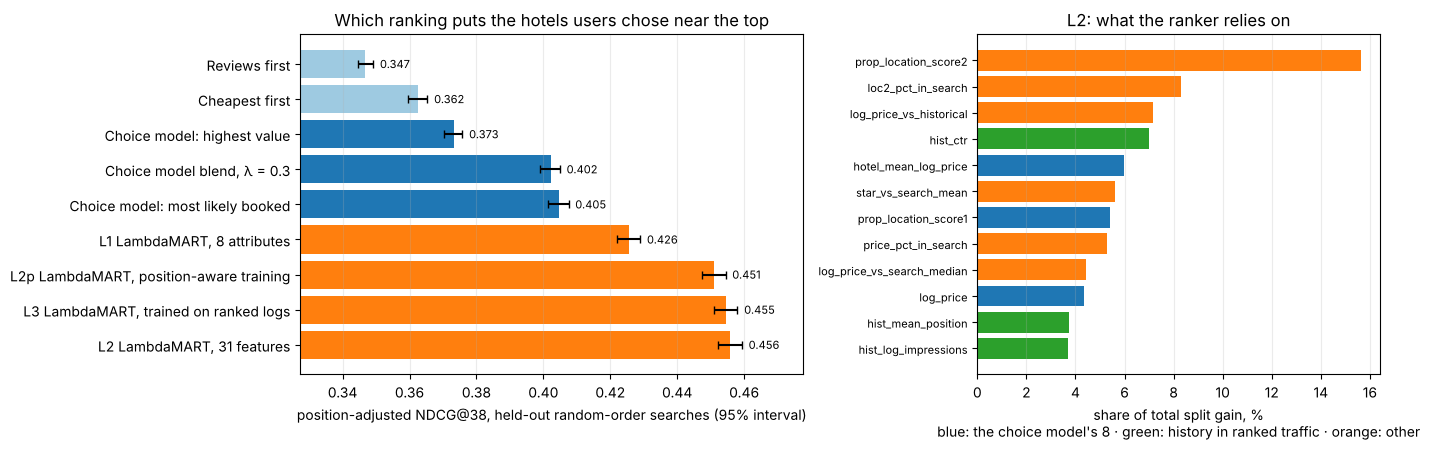

In [9]:
order = list(ndcg_table.sort_values("ndcg").index)
colour = {k: ("#9ecae1" if k.startswith("B") else "#1f77b4" if k.startswith(("M", "blend")) else "#ff7f0e")
          for k in order}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
y = np.arange(len(order))
t = ndcg_table.loc[order]
axes[0].barh(y, t["ndcg"], color=[colour[k] for k in order],
             xerr=[t["ndcg"] - t["ndcg_lo"], t["ndcg_hi"] - t["ndcg"]], capsize=3)
for i, k in enumerate(order):
    axes[0].text(t.loc[k, "ndcg_hi"] + 0.002, i, f"{t.loc[k, 'ndcg']:.3f}", va="center", fontsize=8)
axes[0].set_yticks(y, [LABELS[k] for k in order])
axes[0].invert_yaxis()
axes[0].set_xlim(t["ndcg_lo"].min() * 0.95, t["ndcg_hi"].max() * 1.04)
axes[0].set(xlabel="position-adjusted NDCG@38, held-out random-order searches (95% interval)",
            title="Which ranking puts the hotels users chose near the top")
top = importance.head(12)[::-1]
axes[1].barh(np.arange(len(top)), top.values * 100,
             color=["#1f77b4" if f in ltr.CORE else "#2ca02c" if f in ltr.HOTEL_HISTORY else "#ff7f0e" for f in top.index])
axes[1].set_yticks(np.arange(len(top)), top.index, fontsize=8)
axes[1].set(xlabel="share of total split gain, %\nblue: the choice model's 8 · green: history in ranked traffic · orange: other",
            title="L2: what the ranker relies on")
for ax in axes:
    ax.grid(alpha=0.25, axis="x")
fig.tight_layout()

In [10]:
def r6(v):
    return round(float(v), 6)


record = {
    "status": "exploratory; not part of the phase 4 pre-declared rule",
    "sample": {"train_searches": int(train["srch_id"].nunique()), "early_stopping_searches": int(valid_set["srch_id"].nunique()),
               "heldout_searches": evalset.n_searches, "ranked_train_searches": int(ranked_train["srch_id"].nunique()),
               "history_searches": n_history_searches, "n_boot": N_BOOT},
    "rankers": {k: {"features": r.features, "trees": r.best_iteration, "early_stopping_ndcg": r6(r.valid_ndcg)}
                for k, r in rankers.items()},
    "lightgbm_params": {k: v for k, v in ltr.PARAMS.items() if k != "num_threads"},
    "ndcg": {k: {c: r6(v) for c, v in row.items()} for k, row in ndcg_table.iterrows()},
    "ndcg_checks": {k: {c: r6(v) for c, v in d.items()} for k, d in checks.items()},
    "examination_by_slot": {int(i): r6(theta[i]) for i in range(1, 39)},
    "paired": {k: {"question": v["question"], "ndcg_diff": r6(v["ndcg_diff"]), "ci": [r6(c) for c in v["ci"]],
                   "raw_ndcg_diff": r6(v["raw_ndcg_diff"])} for k, v in paired.items()},
    "booking_model_evaluator": {k: {c: r6(v) for c, v in row.items()} for k, row in evaluator.iterrows()},
    "l2_importance_top12": {k: r6(v) for k, v in importance.head(12).items()},
    "l2_importance_groups": {k: r6(v) for k, v in group_share.items()},
    "fourth_arm_sizing": {"min_detectable_lift": r6(min_lift), "searches_per_day_assumed": DAILY,
                          "designs": {k: {c: (r6(v) if isinstance(v, float) else v) for c, v in s.items()}
                                      for k, s in sizing.items()}},
}
out_path = write_metrics("06_learning_to_rank", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "06_learning_to_rank.png", dpi=150, bbox_inches="tight")

wrote reports/metrics/06_learning_to_rank.json


## Verdict

Rendered from `record`, the dictionary written to `reports/metrics/06_learning_to_rank.json`.

In [11]:
nd, pr, ev = record["ndcg"], record["paired"], record["booking_model_evaluator"]


def diff_text(key: str) -> str:
    d = pr[key]
    sig = "clear of zero" if d["ci"][0] > 0 or d["ci"][1] < 0 else "includes zero"
    return f"{d['ndcg_diff']:+.4f} NDCG [{d['ci'][0]:+.4f}, {d['ci'][1]:+.4f}], {sig}"


best = max(nd, key=lambda k: nd[k]["ndcg"])
ck, g = record["ndcg_checks"], record["booking_model_evaluator"]
feat = pr["L2_extended_random - L1_core_random"]
l2_vs_blend = g["L2_extended_random"]["bookings_per_search"] - g["blend_lambda_0.3"]["bookings_per_search"]
verdict = [
    f"The random arm's tilt flatters rankings that share it, and the position weights remove that: the order actually "
    f"shown scores {ck['order actually shown']['raw']:.4f} NDCG raw and {ck['order actually shown']['adjusted']:.4f} "
    f"adjusted, against {ck['random shuffle']['adjusted']:.4f} for a random shuffle. All figures below are adjusted.",
    f"Best on what users chose: {LABELS[best]}, NDCG@38 {nd[best]['ndcg']:.4f}. It puts the booked hotel in its top 5 for "
    f"{nd[best]['booked_in_top5']:.0%} of bookings, against {nd['blend_lambda_0.3']['booked_in_top5']:.0%} for the phase 5 "
    f"test blend and {nd['B1_reviews_first']['booked_in_top5']:.0%} for reviews first.",
    f"Algorithm: with the same eight attributes, LambdaMART against the choice model is {diff_text('L1_core_random - M1_most_likely_booked')}.",
    f"Features: the other {len(ltr.EXTENDED) - len(ltr.CORE)} add {diff_text('L2_extended_random - L1_core_random')}; "
    f"unadjusted NDCG would have said {feat['raw_ndcg_diff']:+.4f}, because several of them share the tilt. Location score 2 "
    f"carries the most split gain ({record['l2_importance_top12']['prop_location_score2']:.0%}), and the hotel's record in "
    f"Expedia-ranked searches {record['l2_importance_groups']['hotel history in ranked traffic']:.0%}.",
    f"Training data: learning from Expedia-ordered logs is {diff_text('L3_extended_ranked - L2_extended_random')}, and "
    f"the standard position-aware fix is {diff_text('L2p_position_aware - L2_extended_random')}. Position bias was the "
    "central problem for measuring what a slot is worth (phase 2); for ordering hotels by appeal it mattered much less here.",
    (f"The phase 4 booking model {'disagrees' if l2_vs_blend < 0 else 'agrees'}: it rates L2 at "
     f"{g['L2_extended_random']['bookings_per_search']:.4f} bookings per search against "
     f"{g['blend_lambda_0.3']['bookings_per_search']:.4f} for the blend ({l2_vs_blend:+.4f}). Its share of bookings at hotels "
     f"with no reviews is {g['L2_extended_random']['no_review_booking_share']:.2%} against "
     f"{g['B1_reviews_first']['no_review_booking_share']:.2%} for reviews first"
     + (", which the metric framework's guardrail does not allow. "
        if g["L2_extended_random"]["no_review_booking_share"] > g["B1_reviews_first"]["no_review_booking_share"]
        else ", within the metric framework's guardrail. ")
     + "That model sees only eight attributes, and NDCG measures which hotel is chosen, not whether a booking happens "
       "at all, so neither settles it."),
    (lambda base, four: f"A fourth arm costs: {four['n_per_arm']:,} clicked searches per arm and {four['n_total']:,} in total, "
     f"against {base['n_total']:,} as planned (+{four['n_total'] / base['n_total'] - 1:.0%}), or "
     f"{four['days_at_100k_per_day']} days instead of {base['days_at_100k_per_day']} at 100,000 a day. The per-arm size "
     + ("does not change: the value guardrail, not the booking comparisons, still sets it, so the extra cost is the "
        "extra arm." if four["n_per_arm"] == base["n_per_arm"] else "grows because six comparisons share the error rate.")
     )(record["fourth_arm_sizing"]["designs"]["phase 5 as planned (3 arms)"],
       record["fourth_arm_sizing"]["designs"]["add L2 (4 arms, all pairs)"]),
    "Recommendation: L2 is the strongest candidate for which hotel users want. Add it as a fourth arm, with the "
    "no-review guardrail watched, rather than swapping it for the blend (same cost as planned, but it would drop the "
    "arm the booking model rates best). It does not replace the pre-declared arm.",
]
show_verdict("Phase 6 verdict: learning to rank (exploratory)", verdict,
             "The memo's decision 3: whether to pay for a fourth arm.")

### Phase 6 verdict: learning to rank (exploratory)

1. The random arm's tilt flatters rankings that share it, and the position weights remove that: the order actually shown scores 0.4436 NDCG raw and 0.3458 adjusted, against 0.3431 for a random shuffle. All figures below are adjusted.
2. Best on what users chose: L2 LambdaMART, 31 features, NDCG@38 0.4558. It puts the booked hotel in its top 5 for 58% of bookings, against 43% for the phase 5 test blend and 28% for reviews first.
3. Algorithm: with the same eight attributes, LambdaMART against the choice model is +0.0210 NDCG [+0.0179, +0.0238], clear of zero.
4. Features: the other 23 add +0.0301 NDCG [+0.0269, +0.0332], clear of zero; unadjusted NDCG would have said +0.0461, because several of them share the tilt. Location score 2 carries the most split gain (16%), and the hotel's record in Expedia-ranked searches 18%.
5. Training data: learning from Expedia-ordered logs is -0.0012 NDCG [-0.0033, +0.0009], includes zero, and the standard position-aware fix is -0.0049 NDCG [-0.0067, -0.0030], clear of zero. Position bias was the central problem for measuring what a slot is worth (phase 2); for ordering hotels by appeal it mattered much less here.
6. The phase 4 booking model disagrees: it rates L2 at 0.1433 bookings per search against 0.1514 for the blend (-0.0081). Its share of bookings at hotels with no reviews is 1.87% against 1.31% for reviews first, which the metric framework's guardrail does not allow. That model sees only eight attributes, and NDCG measures which hotel is chosen, not whether a booking happens at all, so neither settles it.
7. A fourth arm costs: 616,042 clicked searches per arm and 2,464,168 in total, against 1,848,126 as planned (+33%), or 25 days instead of 19 at 100,000 a day. The per-arm size does not change: the value guardrail, not the booking comparisons, still sets it, so the extra cost is the extra arm.
8. Recommendation: L2 is the strongest candidate for which hotel users want. Add it as a fourth arm, with the no-review guardrail watched, rather than swapping it for the blend (same cost as planned, but it would drop the arm the booking model rates best). It does not replace the pre-declared arm.

**Next:** The memo's decision 3: whether to pay for a fourth arm.